# 01 — Select glaciers from GLIMS

**Purpose.** First stage of the pipeline. Loads the full GLIMS glacier inventory and narrows it to the
~18k glaciers that GlacierView pulls Landsat imagery for, then writes each glacier's outline plus a
padded bounding box for the Earth Engine pull notebooks (03–05).

Selection, in order:
1. Keep outlines drawn after 2005-01-01 (`src_date`).
2. Drop catch-all / umbrella regional centres: Svalbard, Jan Mayen and Bouvet; Various (GlobGlacier);
   the Randolph Glacier Inventory umbrella; Antarctic Peninsula; Various (NSIDC).
3. Keep glaciers with 1 km² < `db_area` < 50 km². The bounds are a judgement call to get typical
   glaciers: nothing tiny, nothing unusually large.
4. Where a `glac_id` has several outlines, keep the first one.
5. Add `bboxes`: the outline's envelope scaled 1.1×, stored as a string of (lon, lat) corners.

The `rgi_examples` / `glob_glacier_examples` / UTM projection cells are left over from a polygon
preview and are unused. The two histogram cells plot the surface-area distribution. Neither changes the
selection.

## Inputs
- **GLIMS polygon shapefile**, 2021-09-14 snapshot:
  `src/glims/data/glims_db_20210914/glims_polygons.{shp,shx,dbf,prj}`. Downloaded from the NSIDC GLIMS
  database (see `CITATIONS.txt` / `README.txt` next to it). Gitignored, so a fresh clone needs it
  re-downloaded. Fields used: `glac_id`, `geog_area`, `src_date`, `db_area`, `geometry`.
- **Matplotlib style**: `src/glacierview/styles/ieee.mplstyle`, via `config.mpl_style()`.
- **Environment**: the project's uv environment as the Jupyter kernel (`uv sync`; the `notebook`
  group is on by default). Needs geopandas, pyproj, shapely and rasterio. No AWS or Earth Engine
  credentials are required.

## Outputs
- `src/glims/data/training_samples/glims_18k_bb.shp` (+ sidecars): read by notebook 02 and the EE pull
  notebooks 03–05.
- `figures/distribution_of_glacier_surface_area.jpg` (tracked).
- `glaciers_per_geog_area.csv`: unique glaciers per `geog_area` *before* filtering. Written to the
  current working directory (normally `notebooks/pipeline/`) and gitignored.

In [45]:
import os
from collections import Counter
from datetime import datetime

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyproj

from glacierview import config

In [46]:
glacier_view_dir = str(config.REPO_ROOT)
figures_dir = os.path.join(glacier_view_dir, "figures")
plt.style.use(config.mpl_style())
glims_path = os.path.join(glacier_view_dir,"src","glims","data","glims_db_20210914","glims_polygons.shp")

In [47]:
df = gpd.read_file(glims_path, index_col = 0)

/Users/mattw/Desktop/projects/GlacierView/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: driver ESRI Shapefile does not support open option INDEX_COL
  return ogr_read(


In [48]:
rgi_examples = iter(df[df['geog_area'] == 'Randolph Glacier Inventory; Umbrella RC for merging the RGI into GLIMS'].geometry)

In [44]:
glob_glacier_examples = iter(df[df['geog_area'] == 'Various (GlobGlacier)'].geometry)

In [27]:
wgs84 = pyproj.CRS('EPSG:4326')
utm = pyproj.CRS('EPSG:32618')

project = pyproj.Transformer.from_crs(wgs84, utm, always_xy=True).transform #this just makes the image larger

In [30]:
df['date'] = [datetime.strptime(dat.split("T")[0], '%Y-%m-%d') for dat in list(df.src_date)] #convert string dates to datetime

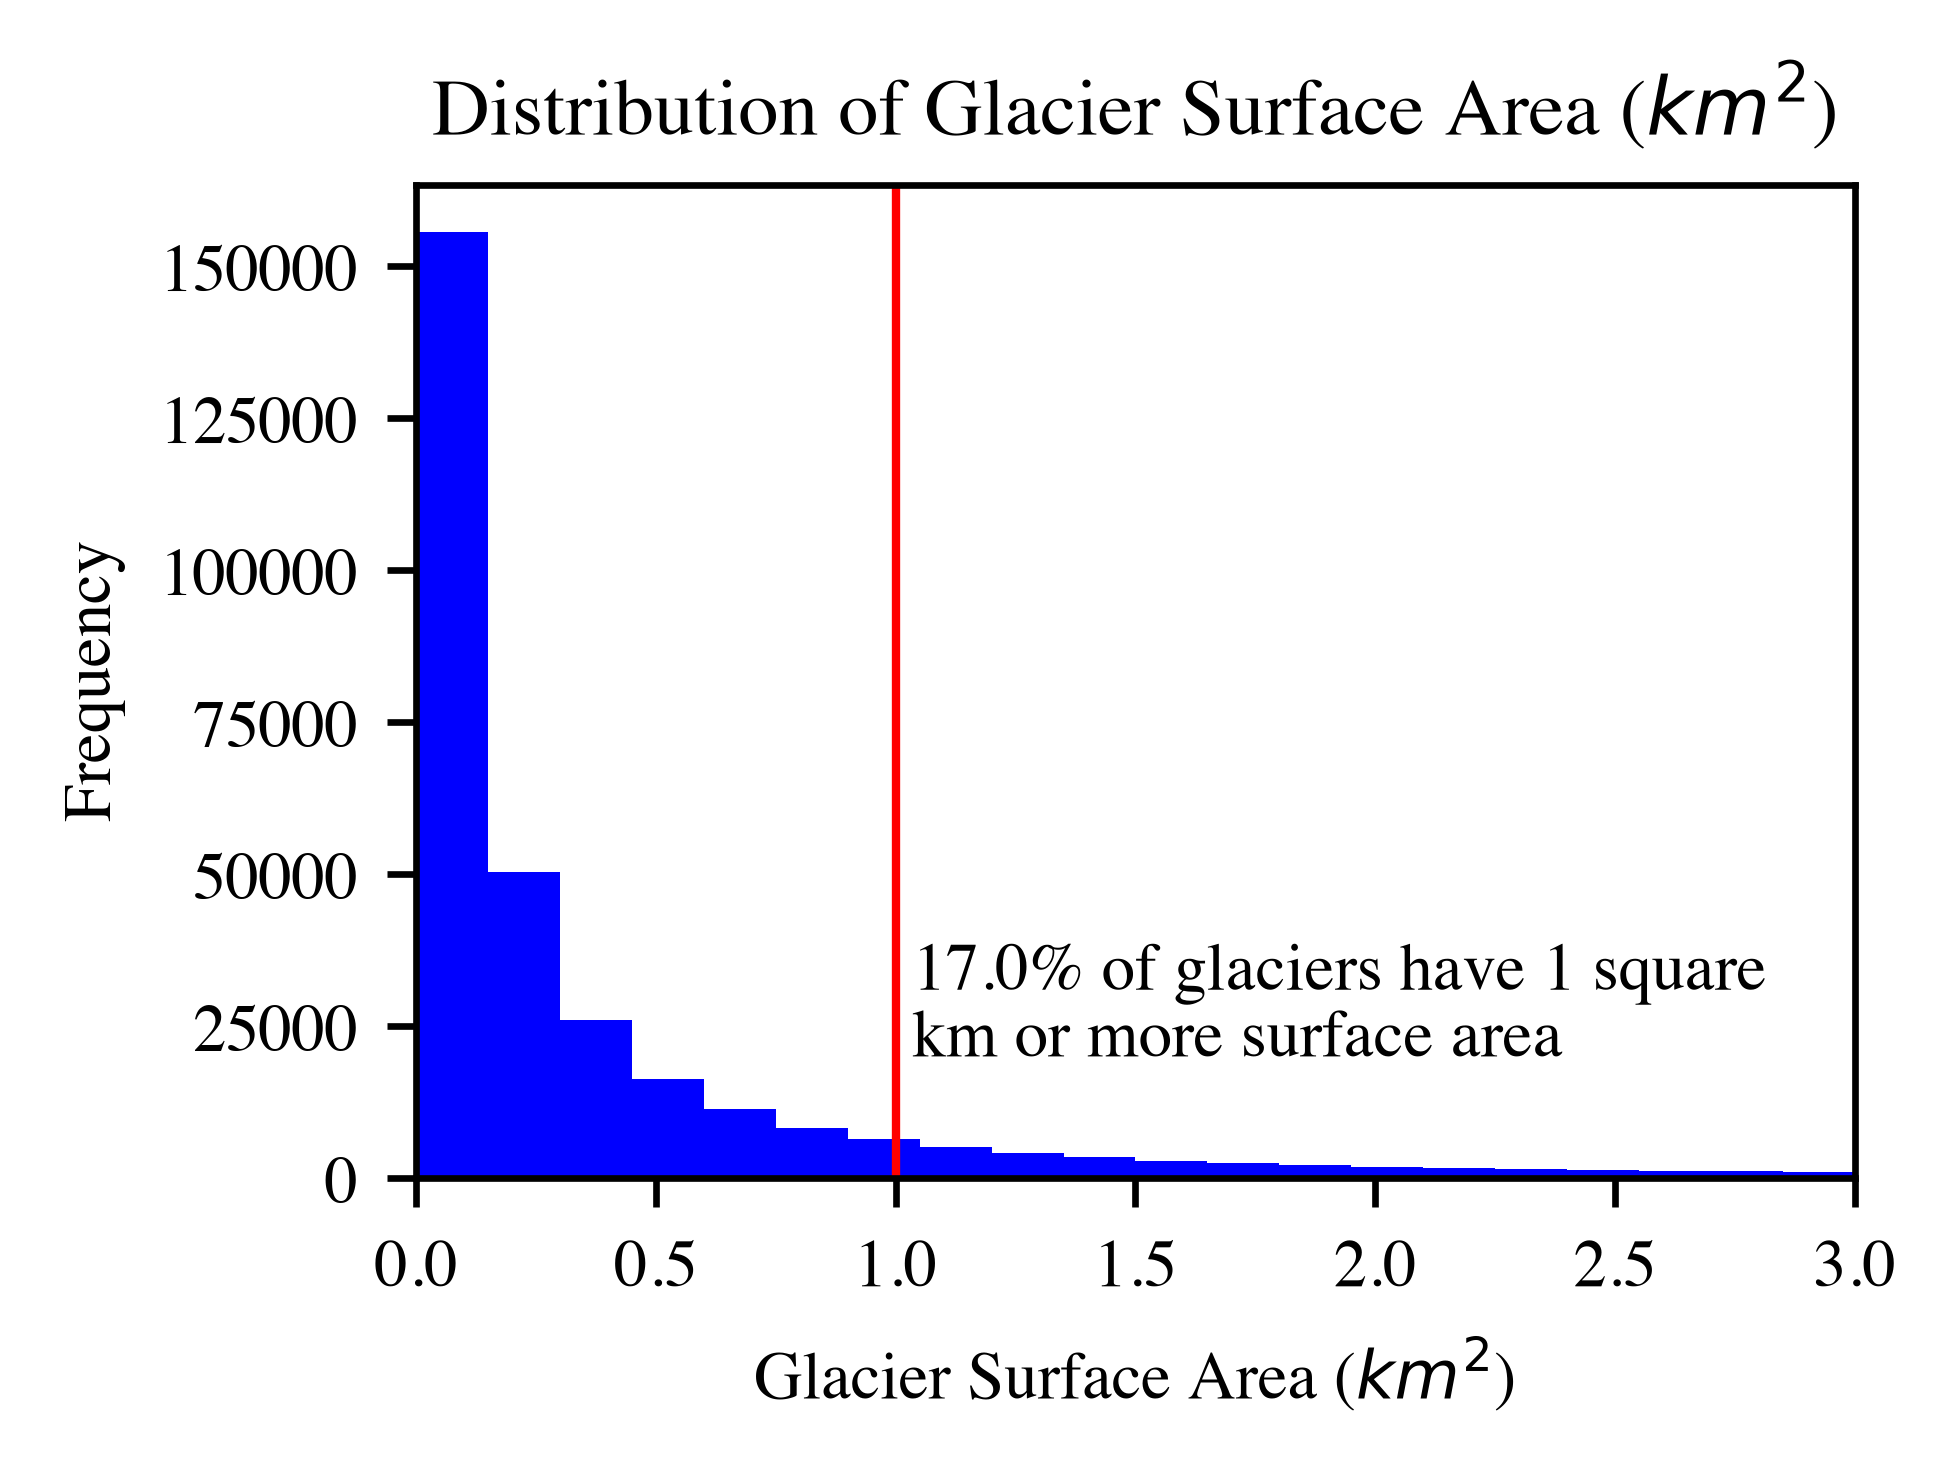

In [31]:
areas = list(df.groupby('glac_id')['db_area'].max())
plt.hist(areas, bins = np.arange(0,50,0.15))
plt.xlim(0,3)
plt.xlabel("Glacier Surface Area ($km^2$)")
plt.ylabel("Frequency")
plt.title("Distribution of Glacier Surface Area ($km^2$)")
plt.axvline(x = 1, color = 'red', linestyle = 'solid')
plt.text(1.0,20000,f' {round(np.mean(np.array(areas) > 1)*100,1)}% of glaciers have 1 square \n km or more surface area')
plt.tight_layout()
plt.savefig(os.path.join(figures_dir,'distribution_of_glacier_surface_area.jpg'), dpi=600)
plt.show()

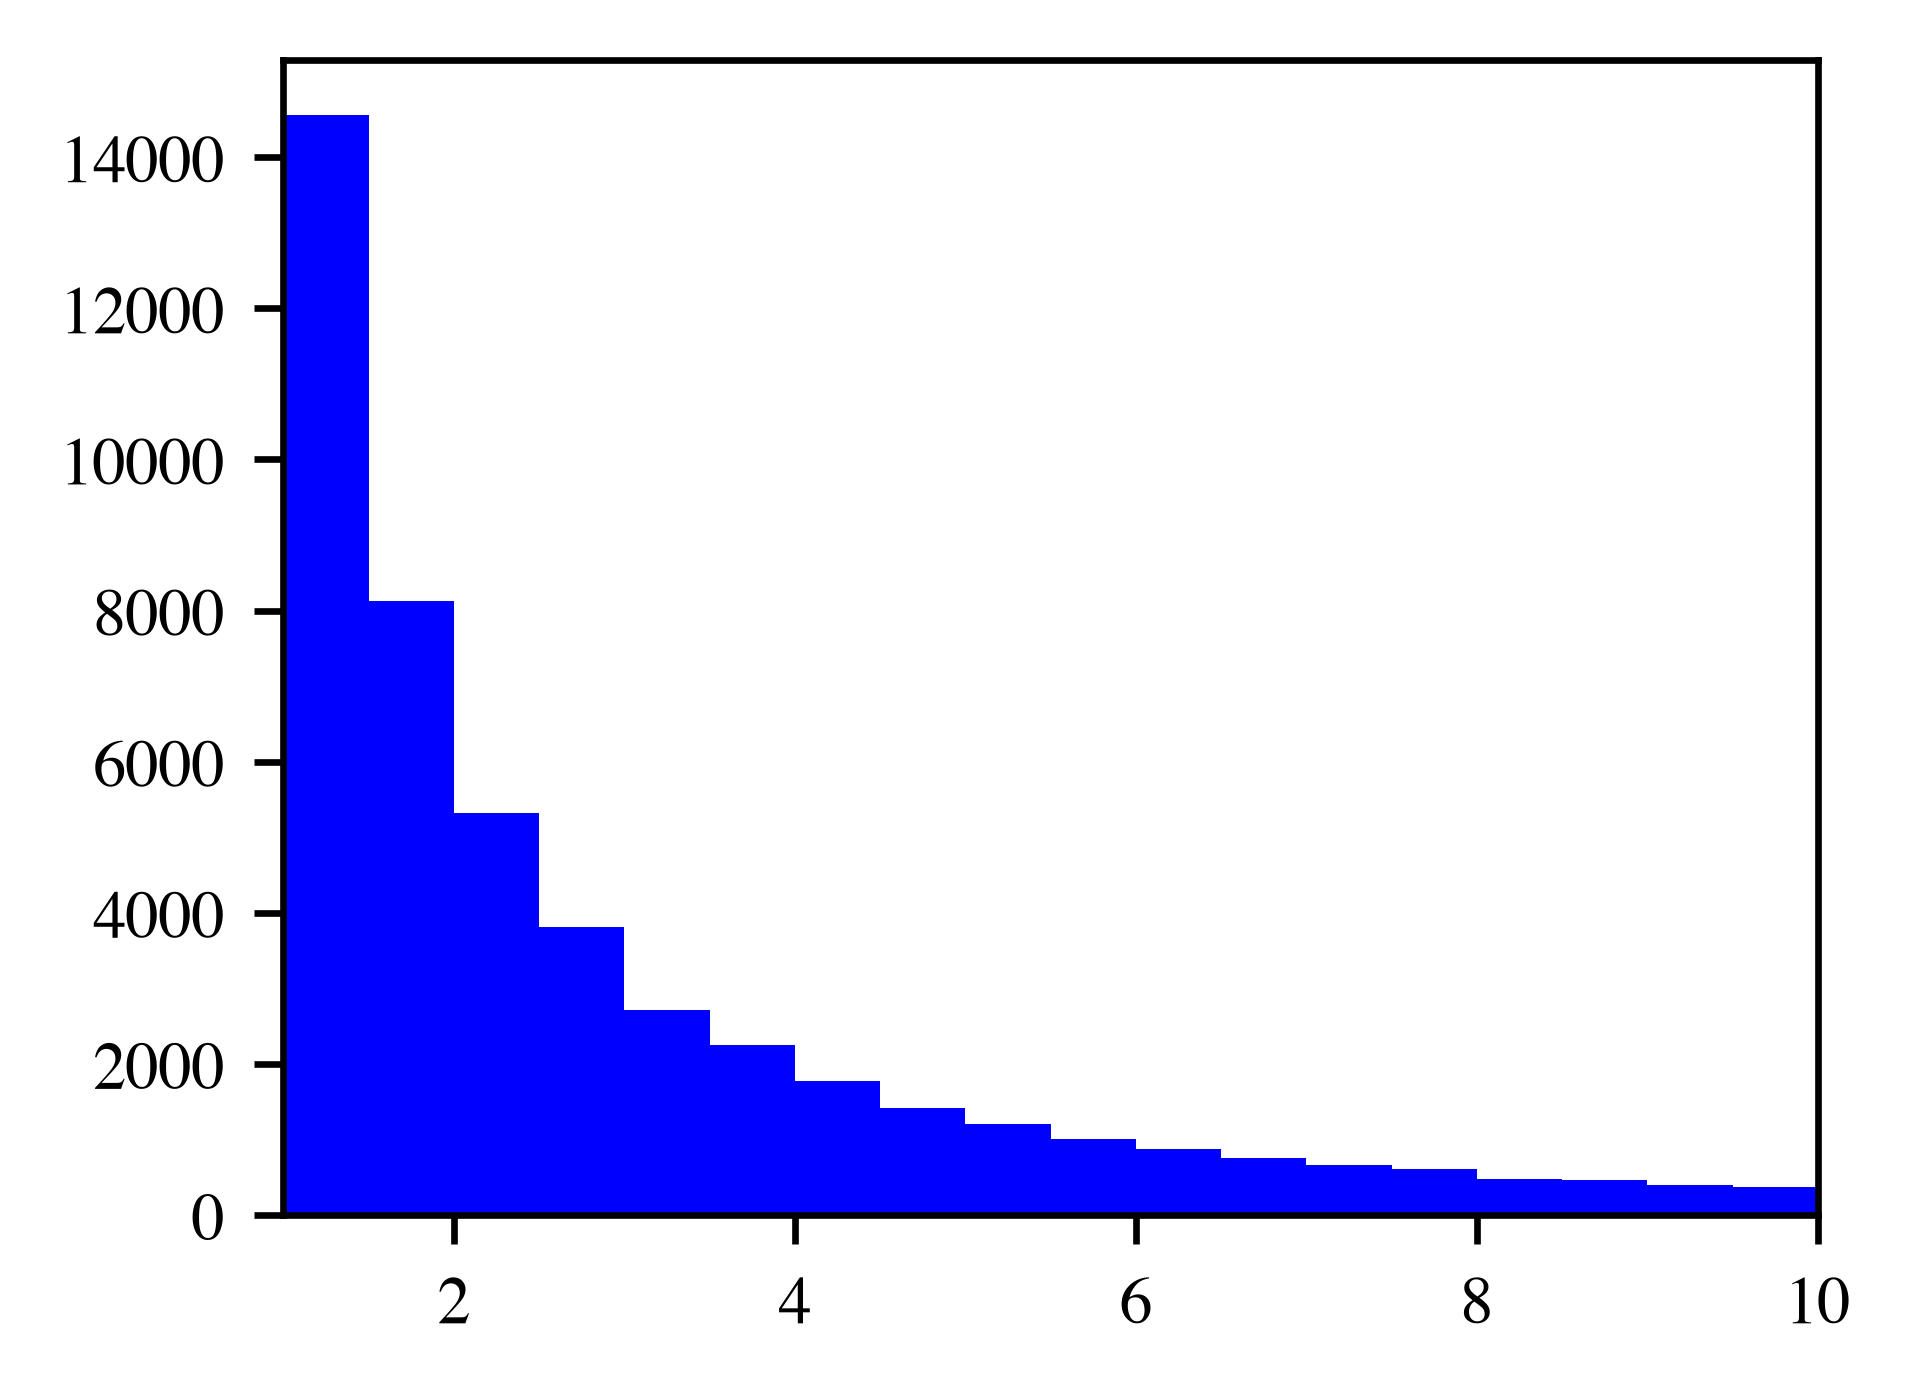

In [32]:
plt.hist(np.array(areas)[np.array(areas) > 1], bins = np.arange(0,50,0.5))
plt.xlim(1,10)
plt.show()

In [33]:
df[['glac_id','geog_area']].groupby('geog_area').glac_id.nunique().to_csv("glaciers_per_geog_area.csv")

In [34]:
print(f"Unique glaciers: {len(pd.unique(df.glac_id))}")
df = df.loc[df['date'] > datetime(2005,1,1)] #select glaciers with polygons drawn after 2005
print(f"Unique glaciers: {len(pd.unique(df.glac_id))}")
df = df[~df['geog_area'].isin(['Svalbard, Jan Mayen, and Bouvet', "Various (GlobGlacier)", 'Randolph Glacier Inventory; Umbrella RC for merging the RGI into GLIMS','Antarctic Peninsula','Various (NSIDC)'])]
print(f"Unique glaciers: {len(pd.unique(df.glac_id))}")
df = df[(df.db_area > 1) & (df.db_area < 50)] #nothing too small, nothing too large
print(f"Unique glaciers: {len(pd.unique(df.glac_id))}")
df = df.iloc[:,:-1] #ESRI shapefiles don't support datetime fields

Unique glaciers: 328115
Unique glaciers: 170363
Unique glaciers: 122212
Unique glaciers: 18093


In [35]:
#remove glac ids which appear more than once in GLIMS (multiple annotations)
df = df.reset_index(drop = True)
clean_copy = df.copy()
s = set()
for i in range(df.shape[0]):
    if df.glac_id[i] in s:
        clean_copy = clean_copy.drop(i, axis = 0)
    else:
        s.add(df.glac_id[i])
df = clean_copy

In [36]:
ids = list(Counter(df.glac_id).keys()) #get list of unique ids
#df['geometry'] = gpd.GeoSeries.from_wkt(df['geometry']) not needed anymore
gdf = gpd.GeoDataFrame(df, geometry = "geometry")

In [37]:
bboxes = []
for i in range(df.shape[0]):
    bboxes.append(list(zip(*np.asarray(gdf.iloc[[i],:].envelope.scale(xfact = 1.1, yfact = 1.1).squeeze().exterior.coords.xy))))
gdf['bboxes'] = [str(bbox) for bbox in bboxes]

In [38]:
gdf.geometry.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [39]:
training_samples_dir = os.path.join(glacier_view_dir,"src","glims","data","training_samples")
os.makedirs(training_samples_dir, exist_ok = True)
gdf.to_file(os.path.join(training_samples_dir,"glims_18k_bb.shp"))

/Users/mattw/Desktop/projects/GlacierView/.venv/lib/python3.12/site-packages/pyogrio/raw.py:733: RuntimeWarning: Value '[(np.float64(-77.60849585000001), np.float64(-8.980091800000002)), (np.float64(-77.60834514999999), np.float64(-8.980091800000002)), (np.float64(-77.60834514999999), np.float64(-8.9799422)), (np.float64(-77.60849585000001), np.float64(-8.9799422)), (np.float64(-77.60849585000001), np.float64(-8.980091800000002))]' of field bboxes has been truncated to 254 characters.  This warning will not be emitted any more for that layer.
  ogr_write(
